STEP 1 : OBTAIN

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/drive/MyDrive/Sleep_health_and_lifestyle_dataset.csv')

# Preview the first few rows
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:
# Check the shape of the dataset (rows, columns)
print("Shape of the dataset:", df.shape)

Shape of the dataset: (374, 13)


In [ ]:
# Check column names
df.columns

Index(['Person ID', 'Gender', 'Age', 'Occupation', 'Sleep Duration',
       'Quality of Sleep', 'Physical Activity Level', 'Stress Level',
       'BMI Category', 'Blood Pressure', 'Heart Rate', 'Daily Steps',
       'Sleep Disorder'],
      dtype='object')

In [ ]:
# Check column data types
df.dtypes

,0
Person ID,int64
Gender,object
Age,int64
Occupation,object
Sleep Duration,float64
Quality of Sleep,int64
Physical Activity Level,int64
Stress Level,int64
BMI Category,object
Blood Pressure,object


In [ ]:
# Check for missing values
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


STEP 2 : SCRUB

In [ ]:
# Check for duplicate rows
duplicate_rows = df[df.duplicated()]
print(f"Number of duplicate rows: {duplicate_rows.shape[0]}")

Number of duplicate rows: 0


In [ ]:
# Check for missing values
df.isnull().sum()

,0
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0


Sleep Disorder has 219 missing values that is label as "None"

In [ ]:
# Replace "None" with "No Disorder"
df['Sleep Disorder'] = df['Sleep Disorder'].fillna("No Disorder")

In [ ]:
# Standardize BMI Category: replace 'Normal' with 'Normal Weight'
df['BMI Category'] = df['BMI Category'].replace('Normal', 'Normal Weight')

In [ ]:
# Split the 'Blood Pressure' column into two new column, "Systolic" and "Diastolic" to extract more information
df[['Systolic', 'Diastolic']] = df['Blood Pressure'].str.split('/', expand=True)

# Convert them to numeric since initially it is in String
df['Systolic'] = pd.to_numeric(df['Systolic'])
df['Diastolic'] = pd.to_numeric(df['Diastolic'])

# Drop the "Blood Preessure" column
df.drop(columns=['Blood Pressure'], inplace=True)

In [ ]:
# Drop the  "Person ID" column
df.drop(columns=['Person ID'], inplace=True)

In [ ]:
df.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,No Disorder,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal Weight,75,10000,No Disorder,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal Weight,75,10000,No Disorder,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


STEP 3 : EXPLORE

In [ ]:
# How many rows and columns
print("Dataset Shape:", df.shape)

# Descriptive statistics of numeric columns
df.describe()

Dataset Shape: (374, 13)


,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps,Systolic,Diastolic
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920,128.553476,84.649733
std,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679,7.748118,6.161611
min,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000,115.000000,75.000000
25%,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000,125.000000,80.000000
50%,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000,130.000000,85.000000
75%,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000,135.000000,90.000000
max,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000,142.000000,95.000000


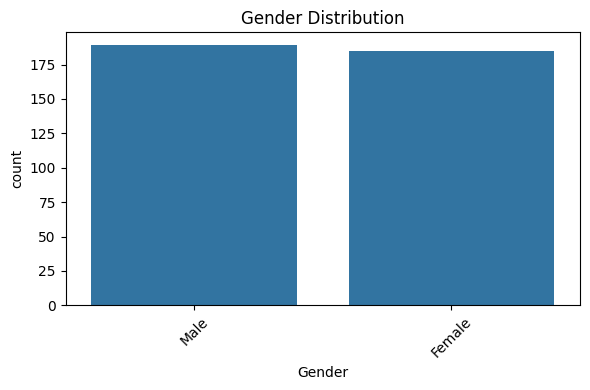

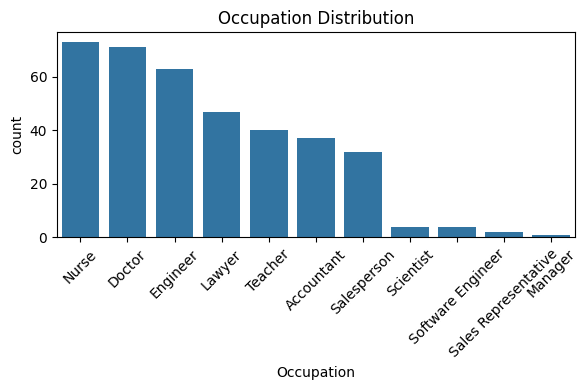

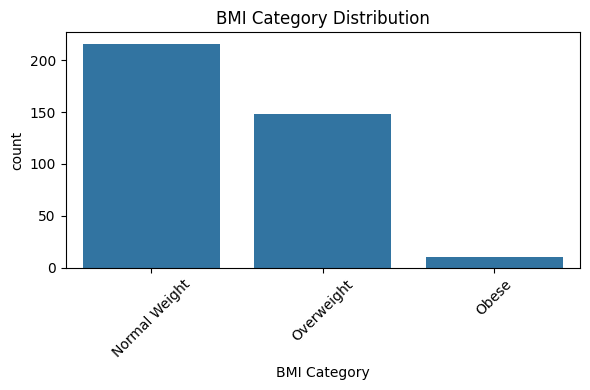

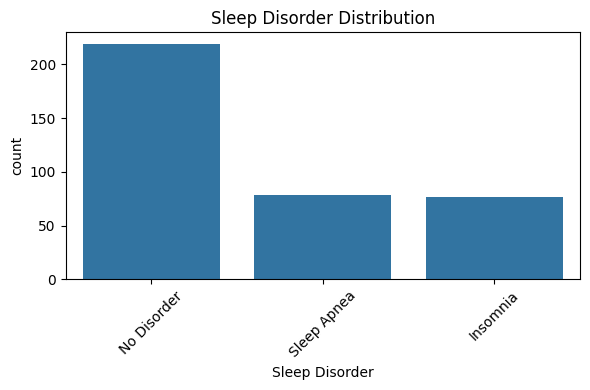

In [ ]:
#List of categorical features to plot
cat_features = ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']

# Loop to plot each one
for col in cat_features:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=col, data=df, order=df[col].value_counts().index)
    plt.title(f'{col} Distribution')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

<Axes: ylabel='Stress Level'>

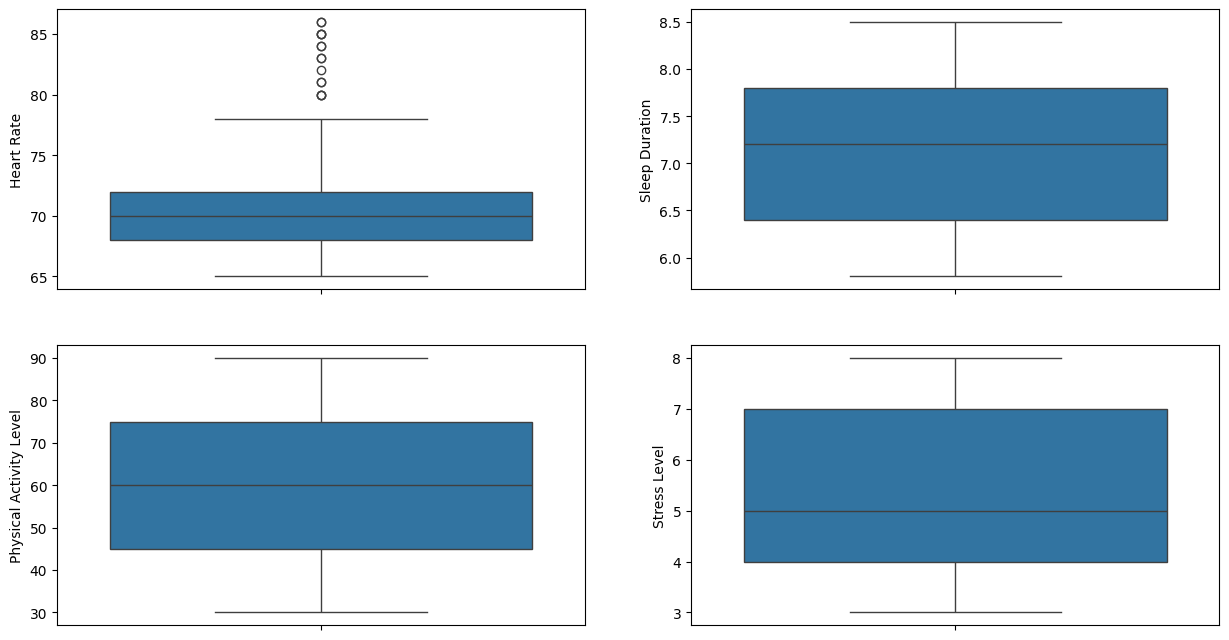

In [ ]:
# Create boxplot to observe distribution of numerical value/outliers (only 4 key features)
import matplotlib.pyplot as plt
import seaborn as sns
fig, axs = plt.subplots(2,2, figsize=(15,8))
sns.boxplot(df['Heart Rate'], ax = axs[0,0])
sns.boxplot(df['Sleep Duration'], ax = axs[0,1])
sns.boxplot(df['Physical Activity Level'], ax = axs[1,0])
sns.boxplot(df['Stress Level'], ax = axs[1,1])

 features like heart rate showed statistical outliers, I chose not to remove them because
-values are likely real and medically significan
-may be critical in detecting or predicting sleep disorders

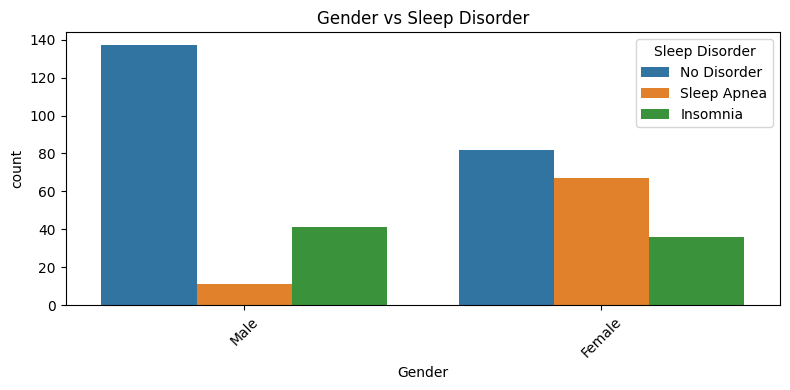

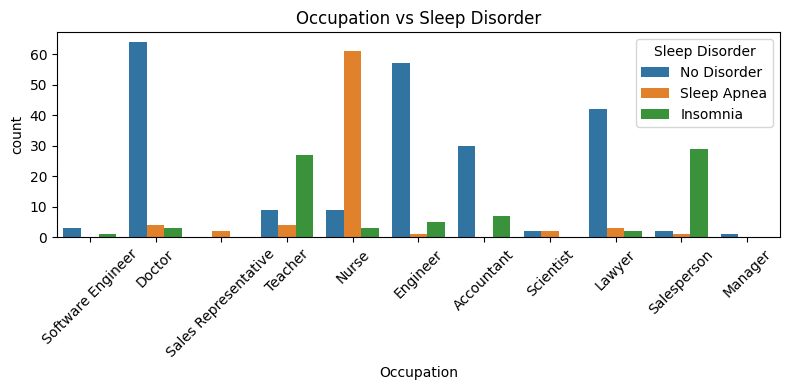

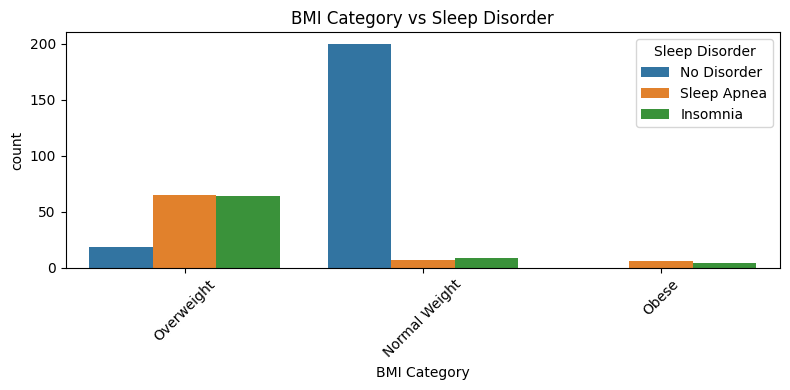

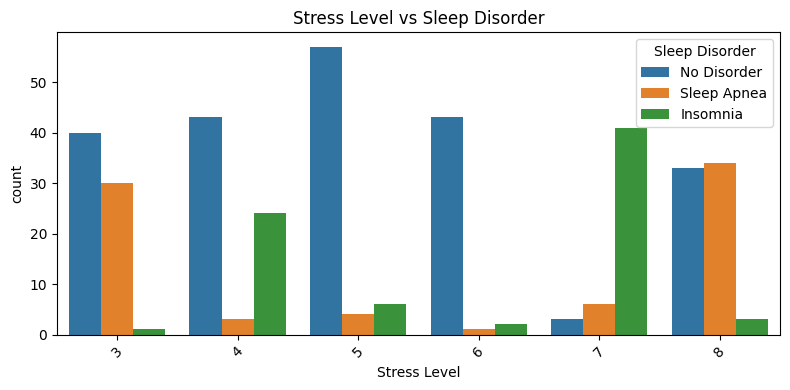

In [ ]:
categorical_cols = ['Gender', 'Occupation', 'BMI Category', 'Stress Level']

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=col, hue='Sleep Disorder', data=df)
    plt.title(f'{col} vs Sleep Disorder')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


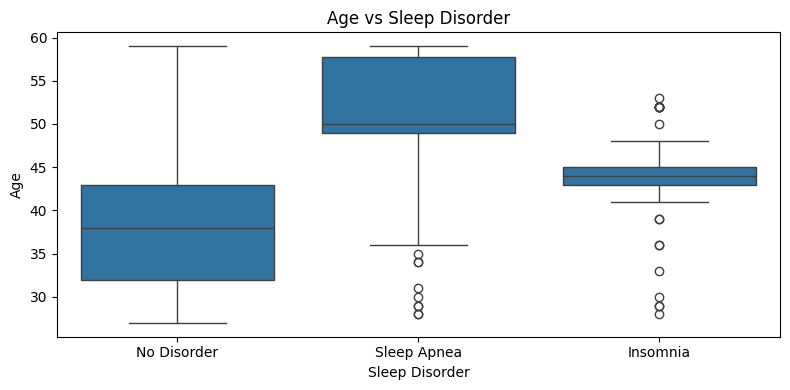

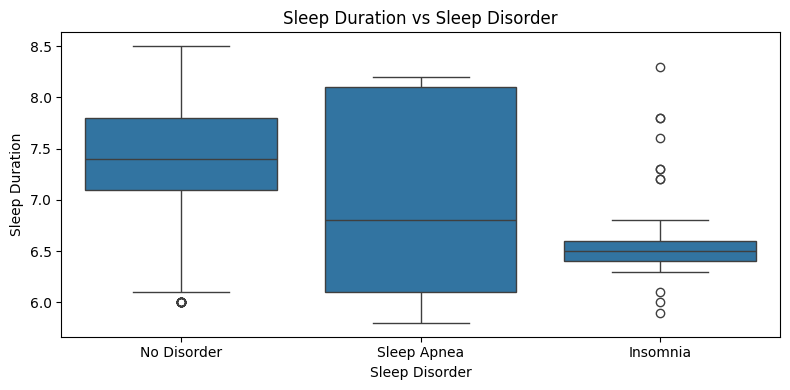

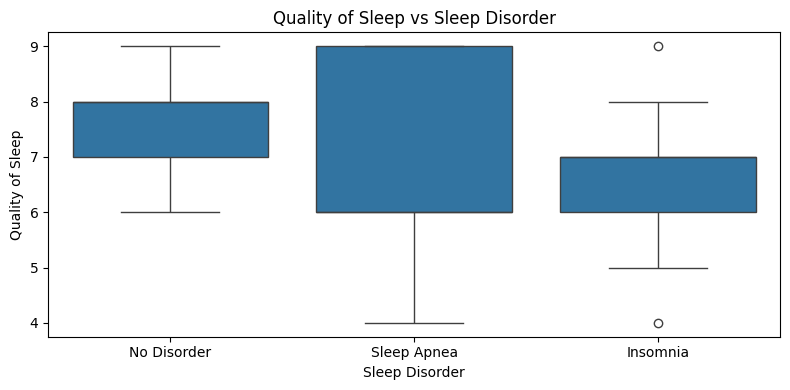

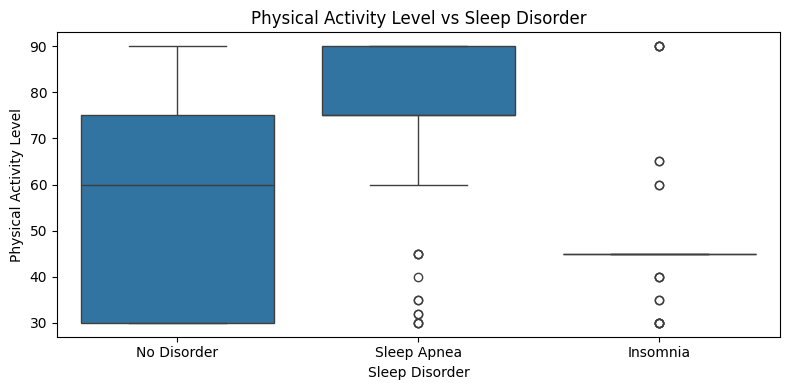

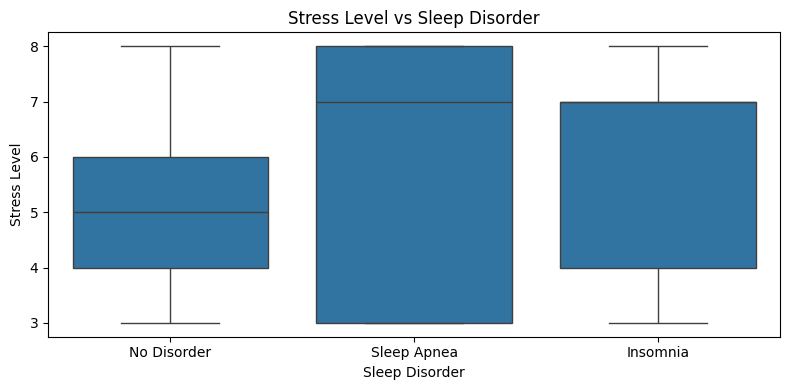

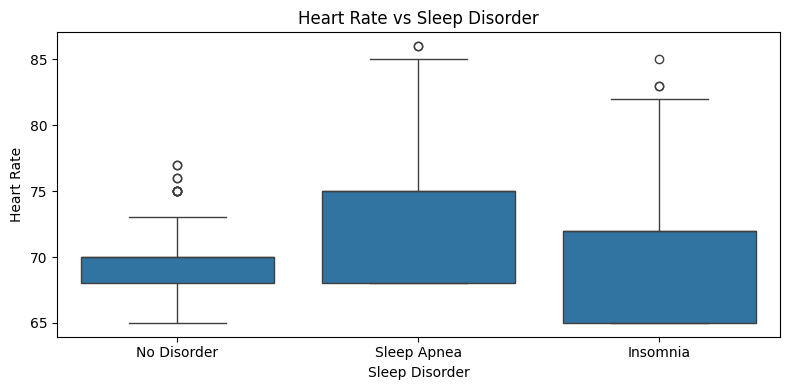

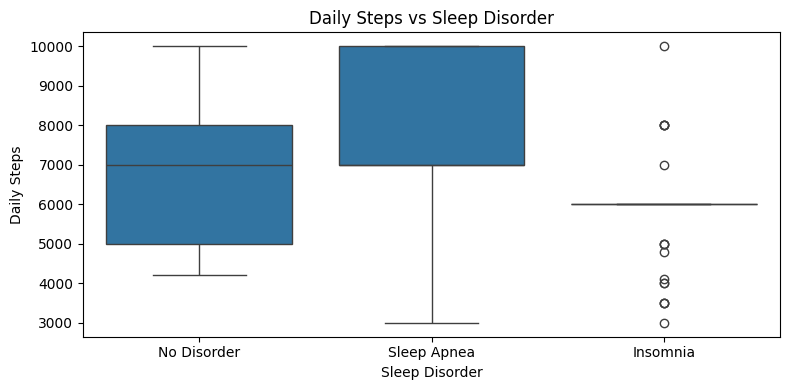

In [ ]:
numerical_cols = ['Age','Sleep Duration','Quality of Sleep','Physical Activity Level','Stress Level','Heart Rate','Daily Steps']

# A plot for each feature one after the other
for col in numerical_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x='Sleep Disorder', y=col, data=df)
    plt.title(f'{col} vs Sleep Disorder')
    plt.xlabel('Sleep Disorder')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

<Axes: >

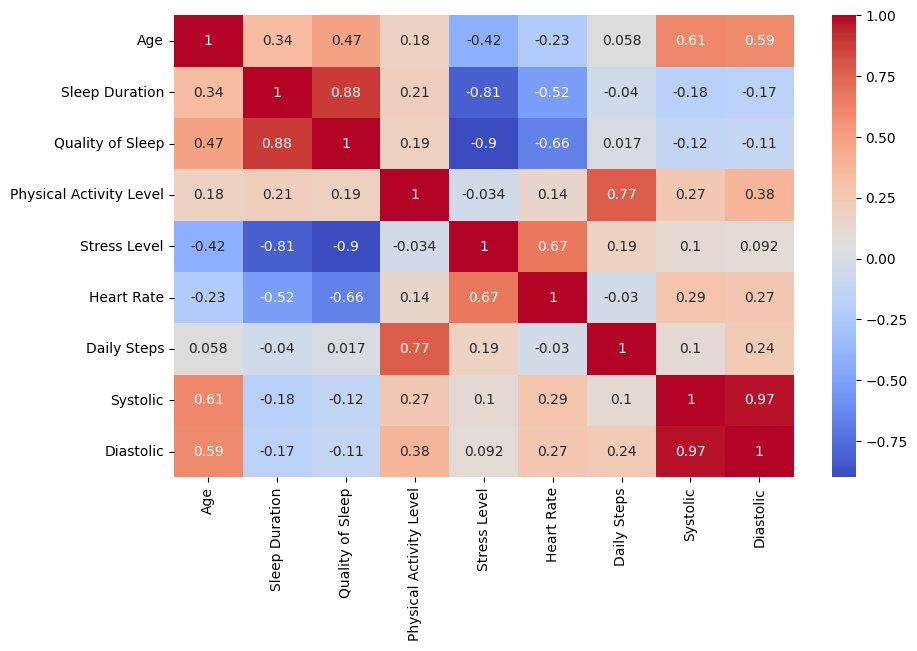

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

# RANDOM FOREST

Accuracy: 0.88

Classification Report:
               precision    recall  f1-score   support

    Insomnia       0.72      0.81      0.76        16
 No Disorder       0.95      0.98      0.97        43
 Sleep Apnea       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75

Confusion Matrix:
 [[13  1  2]
 [ 1 42  0]
 [ 4  1 11]]


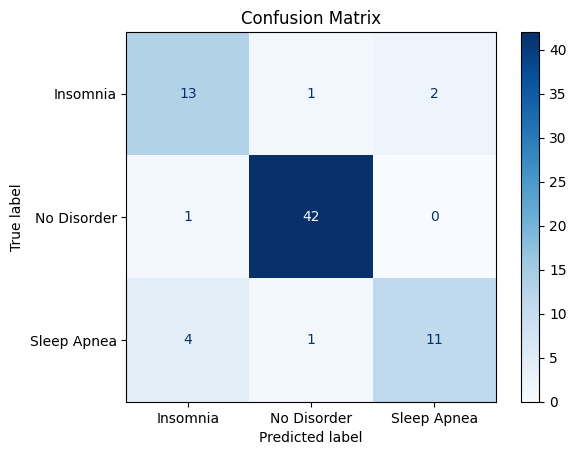

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd # Import pandas if not already imported

# Define features (X) and target (y)
# 'Sleep Disorder' is the target variable
y = df['Sleep Disorder']

# All other columns are features. Drop the target column.
X = df.drop('Sleep Disorder', axis=1)

# Handle categorical features using one-hot encoding
# Select categorical columns again
categorical_cols_for_encoding = ['Gender', 'Occupation', 'BMI Category'] # Exclude 'Sleep Disorder' as it's the target
X = pd.get_dummies(X, columns=categorical_cols_for_encoding, drop_first=True)  # Use drop_first=True to avoid multicollinearity

# Split into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train the Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# make prediction
y_pred = rf_model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Plot the Confusion Matrix
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title("Confusion Matrix")
plt.show()


<ipython-input-41-3864688088>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')


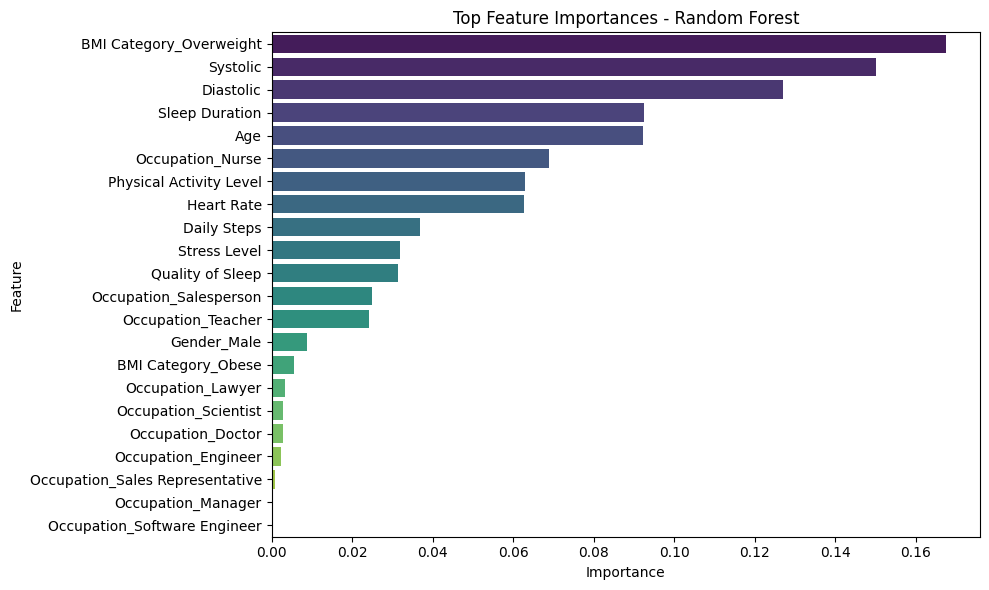

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

importances = rf_model.feature_importances_
features = X.columns

# Create a DataFrame for easier sorting
feat_imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
})

# Sort the DataFrame by importance
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# Plot the sorted importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, palette='viridis')
plt.title("Top Feature Importances - Random Forest")
plt.tight_layout()
plt.show()




In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5)
grid_search.fit(X_train, y_train)

print("Best Params:", grid_search.best_params_)


Best Params: {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}


Tuned Model Accuracy: 0.88

Tuned Model Classification Report:
               precision    recall  f1-score   support

    Insomnia       0.72      0.81      0.76        16
 No Disorder       0.95      0.98      0.97        43
 Sleep Apnea       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75

Tuned Model Confusion Matrix:
 [[13  1  2]
 [ 1 42  0]
 [ 4  1 11]]


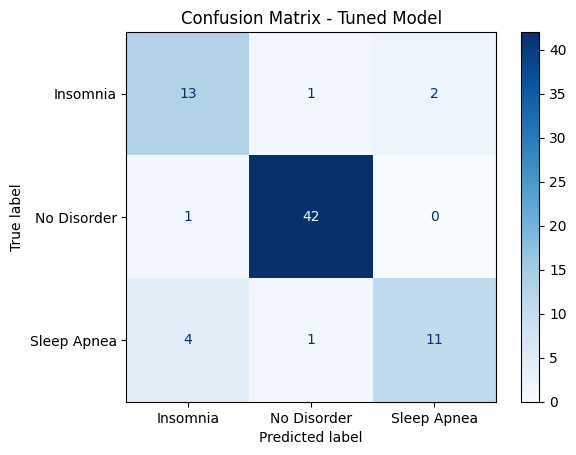

In [ ]:
# Get the best model from grid search
best_rf = grid_search.best_estimator_

# Retrain the best model (usually optional but safe)
best_rf.fit(X_train, y_train)

# Make predictions with the best model
y_pred_best = best_rf.predict(X_test)

# Evaluate the best model
print("Tuned Model Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nTuned Model Classification Report:\n", classification_report(y_test, y_pred_best))
print("Tuned Model Confusion Matrix:\n", confusion_matrix(y_test, y_pred_best))

# Display the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test, cmap='Blues')
plt.title("Confusion Matrix - Tuned Model")
plt.show()
